In [1]:
import pandas as pd, sqlite3
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
DB_PATH = ROOT / 'collections.db'

conn = sqlite3.connect(DB_PATH)
print('SQLite version:', sqlite3.sqlite_version)
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn))

SQLite version: 3.35.5
   name
0   pos
1  prev


In [2]:
def run_file(path):
    with open(path) as f:
        conn.executescript(f.read())

def query_file(path):
    with open(path) as f:
        return pd.read_sql(f.read(), conn)

In [3]:
run_file(ROOT / 'sql' / '01_paired_view.sql')
pd.read_sql("SELECT * FROM paired WHERE sk_id_prev = (SELECT MIN(sk_id_prev) FROM pos) ORDER BY months_balance LIMIT 15", conn)

,sk_id_prev,sk_id_curr,months_balance,sk_dpd,name_contract_status,bucket,next_bucket,next_dpd,next_month
0,1000033,333787,-17,0,Approved,0 Current,0 Current,0.0,-16.0
1,1000033,333787,-16,0,Active,0 Current,0 Current,0.0,-15.0
2,1000033,333787,-15,0,Active,0 Current,0 Current,0.0,-14.0
3,1000033,333787,-14,0,Active,0 Current,0 Current,0.0,-13.0
4,1000033,333787,-13,0,Active,0 Current,0 Current,0.0,-12.0
5,1000033,333787,-12,0,Active,0 Current,0 Current,0.0,-11.0
6,1000033,333787,-11,0,Active,0 Current,Closed,0.0,-10.0
7,1000033,333787,-10,0,Completed,Closed,None,NaN,NaN


In [6]:
roll = query_file(ROOT / 'sql' / '02_roll_rates.sql')
print(roll)
roll.to_csv(ROOT / 'outputs' / 'roll_rates.csv', index=False)

       bucket next_bucket       n   pct
0   0 Current   0 Current  714528  91.1
1   0 Current        1-30    8796   1.1
2   0 Current       31-60      25   0.0
3   0 Current         90+      27   0.0
4   0 Current      Closed   60751   7.7
5        1-30   0 Current    6572  45.8
6        1-30        1-30    5805  40.4
7        1-30       31-60     641   4.5
8        1-30       61-90      14   0.1
9        1-30      Closed    1325   9.2
10      31-60   0 Current      80  11.5
11      31-60        1-30      54   7.7
12      31-60       31-60      42   6.0
13      31-60       61-90     432  61.9
14      31-60         90+       9   1.3
15      31-60      Closed      81  11.6
16      61-90   0 Current      11   2.4
17      61-90        1-30       2   0.4
18      61-90       31-60       2   0.4
19      61-90       61-90       3   0.7
20      61-90         90+     416  91.4
21      61-90      Closed      21   4.6
22        90+   0 Current     199   2.0
23        90+        1-30       2   0.0


In [7]:
print(roll.groupby('bucket')['pct'].sum())
roll.pivot(index='bucket', columns='next_bucket', values='pct').fillna(0)

bucket
0 Current     99.9
1-30         100.0
31-60        100.0
61-90         99.9
90+           99.9
Name: pct, dtype: float64


next_bucket,0 Current,1-30,31-60,61-90,90+,Closed
bucket,,,,,,
0 Current,91.1,1.1,0.0,0.0,0.0,7.7
1-30,45.8,40.4,4.5,0.1,0.0,9.2
31-60,11.5,7.7,6.0,61.9,1.3,11.6
61-90,2.4,0.4,0.4,0.7,91.4,4.6
90+,2.0,0.0,0.0,0.0,95.7,2.2


In [11]:
run_file(ROOT / 'sql' / '03_overdue_base.sql')
print(pd.read_sql('SELECT COUNT(*) AS n FROM overdue_base', conn))
pd.read_sql('SELECT * FROM overdue_base LIMIT 10', conn)

       n
0  14580


,sk_id_prev,sk_id_curr,months_balance,sk_dpd,bucket,bad_next,exposure
0,1182516,267782,-3,1,1-30,0,451777.5
1,1984290,316076,-77,18,1-30,0,77962.5
2,1028290,230321,-9,2,1-30,0,30550.5
3,2354135,149457,-93,19,1-30,0,39204.0
4,1013498,235505,-11,8,1-30,0,450000.0
5,1016893,412417,-77,29,1-30,0,37345.5
6,1852906,422437,-79,25,1-30,0,70060.5
7,1852906,422437,-78,26,1-30,0,70060.5
8,2280885,366895,-63,1,1-30,0,35563.5
9,2280885,366895,-62,1,1-30,0,35563.5


In [9]:
print(pd.read_sql('SELECT * FROM overdue_base ORDER BY RANDOM() LIMIT 10', conn))
pd.read_sql("""SELECT bucket, COUNT(*) AS n, SUM(bad_next) AS bad
               FROM overdue_base GROUP BY bucket ORDER BY bucket""", conn)

   sk_id_prev  sk_id_curr  months_balance  sk_dpd bucket  bad_next  exposure
0     1589884      377940             -39       7   1-30         0  135000.0
1     2283790      315740             -44       2   1-30         0   95940.0
2     1442108      382712             -59       6   1-30         0   46966.5
3     2773276      414330             -71       9   1-30         0   29074.5
4     2409784      129454             -76       2   1-30         0  308718.0
5     1747143      152652             -27       8   1-30         0  556717.5
6     2623323      197740             -37       2   1-30         0  270000.0
7     2343415      205304             -11       5   1-30         0   54405.0
8     1136557      178460             -74       8   1-30         0   63706.5
9     1914577      371045             -30       2   1-30         0   52236.0


,bucket,n,bad
0,1-30,13607,576
1,31-60,601,407
2,61-90,372,345
3,90+,4864,4566


In [12]:
summary = pd.read_sql("""
  SELECT bucket, COUNT(*) AS account_months,
         ROUND(100.0 * SUM(bad_next) / COUNT(*), 1) AS pct_bad_next
  FROM overdue_base GROUP BY bucket ORDER BY bucket""", conn)
print(summary)
summary.to_csv(ROOT / 'outputs' / 'bucket_summary.csv', index=False)

pd.read_sql('SELECT * FROM overdue_base', conn).to_csv(ROOT / 'outputs' / 'overdue_base.csv', index=False)
print('Saved')

  bucket  account_months  pct_bad_next
0   1-30           13607           4.2
1  31-60             601          62.1
2  61-90             372          92.5
Saved


In [13]:
roll.pivot(index='bucket', columns='next_bucket', values='pct').fillna(0)

next_bucket,0 Current,1-30,31-60,61-90,90+,Closed
bucket,,,,,,
0 Current,91.1,1.1,0.0,0.0,0.0,7.7
1-30,45.8,40.4,4.5,0.1,0.0,9.2
31-60,11.5,7.7,6.0,61.9,1.3,11.6
61-90,2.4,0.4,0.4,0.7,91.4,4.6
90+,2.0,0.0,0.0,0.0,95.7,2.2


In [14]:
base = pd.read_sql('SELECT * FROM overdue_base', conn)
train = base[base['sk_id_curr'] % 2 == 0]
test  = base[base['sk_id_curr'] % 2 == 1].copy()
print(len(train), len(test))
print(train['bad_next'].sum(), test['bad_next'].sum())

7260 7320
662 631


In [15]:
p_bad = train.groupby('bucket')['bad_next'].mean()
print(p_bad)
test['p_bad'] = test['bucket'].map(p_bad)
test['score'] = test['p_bad'] * test['exposure']
test['risky_exposure'] = test['bad_next'] * test['exposure']

bucket
1-30     0.044122
31-60    0.603175
61-90    0.910995
Name: bad_next, dtype: float64


In [16]:
def capture(df, order_col, pct):
    n = int(len(df) * pct)
    chosen = df.sort_values(order_col, ascending=False).head(n)
    return chosen['risky_exposure'].sum() / df['risky_exposure'].sum()

rows = []
for p in [0.05, 0.10, 0.20, 0.30, 0.50]:
    rows.append({'capacity_pct': p,
                 'baseline_capture': capture(test, 'sk_dpd', p),
                 'score_capture':    capture(test, 'score', p),
                 'random_capture':   p})
gain = pd.DataFrame(rows).round(3)
print(gain)
gain.to_csv(ROOT / 'outputs' / 'gain_table.csv', index=False)

   capacity_pct  baseline_capture  score_capture  random_capture
0          0.05             0.457          0.390            0.05
1          0.10             0.597          0.488            0.10
2          0.20             0.686          0.577            0.20
3          0.30             0.807          0.627            0.30
4          0.50             0.890          0.724            0.50


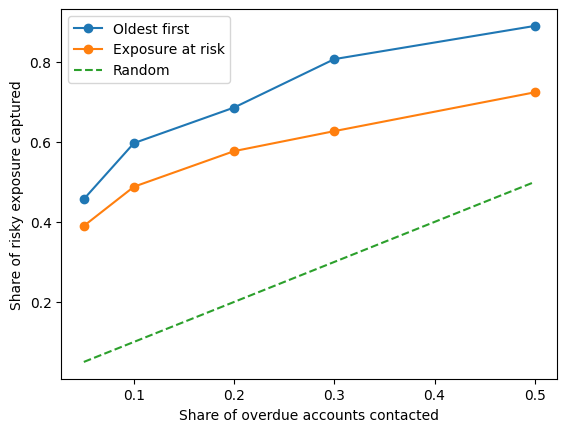

In [17]:
import matplotlib.pyplot as plt
plt.plot(gain['capacity_pct'], gain['baseline_capture'], marker='o', label='Oldest first')
plt.plot(gain['capacity_pct'], gain['score_capture'], marker='o', label='Exposure at risk')
plt.plot(gain['capacity_pct'], gain['random_capture'], linestyle='--', label='Random')
plt.xlabel('Share of overdue accounts contacted'); plt.ylabel('Share of risky exposure captured')
plt.legend(); plt.show()

In [18]:
print('NaN scores:', test['score'].isna().sum())   # should be 0

t1 = train[train['bucket'] == '1-30'].copy()
t1['dpd_band'] = pd.cut(t1['sk_dpd'], [0, 5, 10, 15, 20, 25, 30])
print(t1.groupby('dpd_band', observed=True)['bad_next'].agg(['count', 'mean']).round(3))

NaN scores: 0
          count   mean
dpd_band              
(0, 5]     3255  0.028
(5, 10]    1640  0.038
(10, 15]    894  0.056
(15, 20]    496  0.075
(20, 25]    315  0.076
(25, 30]    154  0.227


In [19]:
bins = [0, 5, 10, 15, 20, 25, 30, 45, 60, 75, 90]
train = train.copy()
train['band'] = pd.cut(train['sk_dpd'], bins, labels=False)
test['band']  = pd.cut(test['sk_dpd'],  bins, labels=False)

p_band = train.groupby('band')['bad_next'].mean()
test['p_band']   = test['band'].map(p_band)
test['score_v2'] = test['p_band'] * test['exposure']

rows = []
for p in [0.05, 0.10, 0.20, 0.30, 0.50]:
    rows.append({'capacity_pct': p,
                 'baseline_capture': capture(test, 'sk_dpd', p),
                 'v1_bucket_x_exposure': capture(test, 'score', p),
                 'v2_dpdband_x_exposure': capture(test, 'score_v2', p),
                 'v3_band_then_exposure': capture(test, ['band', 'exposure'], p),
                 'random_capture': p})
gain2 = pd.DataFrame(rows).round(3)
print(gain2)
gain2.to_csv(ROOT / 'outputs' / 'gain_table_v2.csv', index=False)

   capacity_pct  baseline_capture  v1_bucket_x_exposure  \
0          0.05             0.457                 0.390   
1          0.10             0.597                 0.488   
2          0.20             0.686                 0.577   
3          0.30             0.807                 0.627   
4          0.50             0.890                 0.724   

   v2_dpdband_x_exposure  v3_band_then_exposure  random_capture  
0                  0.437                  0.453            0.05  
1                  0.522                  0.590            0.10  
2                  0.632                  0.685            0.20  
3                  0.689                  0.797            0.30  
4                  0.793                  0.886            0.50  


In [20]:
pd.read_sql("""
  SELECT COUNT(*) AS loan_month_rows,
         SUM(CASE WHEN a.sk_id_prev IS NULL THEN 1 ELSE 0 END) AS rows_without_amount
  FROM pos p
  LEFT JOIN prev a ON a.sk_id_prev = p.sk_id_prev""", conn)

,loan_month_rows,rows_without_amount
0,897388,30299


In [21]:
pd.read_sql("""
  SELECT p.name_contract_status, COUNT(*) AS n
  FROM pos p LEFT JOIN prev a ON a.sk_id_prev = p.sk_id_prev
  WHERE a.sk_id_prev IS NULL
  GROUP BY p.name_contract_status ORDER BY n DESC""", conn)

,NAME_CONTRACT_STATUS,n
0,Active,24974
1,Completed,4747
2,Demand,497
3,Amortized debt,48
4,Signed,27
5,Returned to the store,6


In [22]:
pd.read_sql("""
  SELECT COUNT(*) AS overdue_rows,
         SUM(CASE WHEN a.sk_id_prev IS NULL THEN 1 ELSE 0 END) AS overdue_rows_without_amount
  FROM paired p
  LEFT JOIN prev a ON a.sk_id_prev = p.sk_id_prev
  WHERE p.name_contract_status = 'Active'
    AND p.sk_dpd BETWEEN 1 AND 90
    AND p.next_month = p.months_balance + 1""", conn)

,overdue_rows,overdue_rows_without_amount
0,15500,920
